###  ML Experiment Number 10


Student Name :Utkarsh Vishwanath Parulekar

Batch :CS03


Roll Number :CS39



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:

# Load Mall Customer Segmentation Dataset

import pandas as pd
from google.colab import files

# Upload dataset
uploaded = files.upload()

# Load dataset
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# Display first five rows
print("Dataset loaded successfully!")
print(df.head())

# Display dataset shape
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())


Saving Mall_Customers.csv to Mall_Customers.csv
Dataset loaded successfully!
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:

# Task 2: Feature Selection and Standardization

from sklearn.preprocessing import StandardScaler

# Select features
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Display original features
print("Selected Features:")
print(X.head())

# Display standardized features
print("\nStandardized Features:")
print(pd.DataFrame(
    X_scaled,
    columns=['Annual Income (k$)', 'Spending Score (1-100)']
).head())

# Display mean and standard deviation
print("\nMean of scaled features:")
print(X_scaled.mean(axis=0))

print("\nStandard deviation of scaled features:")
print(X_scaled.std(axis=0))


Selected Features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Standardized Features:
   Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980

Mean of scaled features:
[-2.13162821e-16 -1.46549439e-16]

Standard deviation of scaled features:
[1. 1.]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

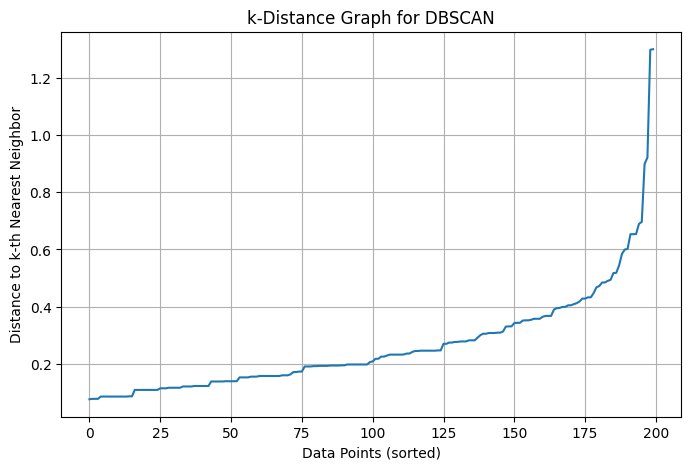

In [ ]:

# Task 3: Hyperparameter Selection via k-Distance Graph

from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Set min_samples
min_samples = 5

# Compute nearest neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort k-distances
k_distances = np.sort(distances[:, min_samples - 1])

# Plot k-distance graph
plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Data Points (sorted)")
plt.ylabel("Distance to k-th Nearest Neighbor")
plt.title("k-Distance Graph for DBSCAN")
plt.grid(True)
plt.show()


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [ ]:

# Task 4: Implement DBSCAN Clustering

from sklearn.cluster import DBSCAN
import numpy as np

# Set DBSCAN parameters
eps_value = 0.3  # Replace with epsilon identified from Task 3
min_samples = 5

# Create DBSCAN model
dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)

# Fit model and predict cluster labels
labels = dbscan.fit_predict(X_scaled)

# Add cluster labels to the dataset
df['Cluster'] = labels

# Display cluster assignments
print("Cluster assignments:")
print(df[['Annual Income (k$)', 'Spending Score (1-100)', 'Cluster']].head(10))

# Display number of clusters and noise points
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("\nNumber of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Unique cluster labels:", np.unique(labels))


Cluster assignments:
   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        2
1                  15                      81        0
2                  16                       6        1
3                  16                      77        0
4                  17                      40        2
5                  17                      76        0
6                  18                       6        1
7                  18                      94       -1
8                  19                       3        1
9                  19                      72        0

Number of clusters: 7
Number of noise points: 35
Unique cluster labels: [-1  0  1  2  3  4  5  6]


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:

# Task 5: Evaluate DBSCAN Clustering

from sklearn.metrics import silhouette_score
import numpy as np

# Count clusters excluding noise points (-1)
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

# Count noise points
n_noise = np.sum(labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Percentage of noise points:", round((n_noise / len(labels)) * 100, 2), "%")

# Calculate Silhouette Score
# Exclude noise points from evaluation
non_noise = labels != -1
cluster_labels = labels[non_noise]
X_non_noise = X_scaled[non_noise]

if len(set(cluster_labels)) > 1 and len(set(cluster_labels)) < len(cluster_labels):
    score = silhouette_score(X_non_noise, cluster_labels)
    print("Silhouette Score:", round(score, 4))
else:
    print("Silhouette Score cannot be calculated because at least two clusters are required.")

# Display cluster-wise data counts
print("\nCluster-wise data counts:")
for cluster in sorted(set(labels)):
    if cluster == -1:
        print("Noise points:", np.sum(labels == -1))
    else:
        print("Cluster", cluster, ":", np.sum(labels == cluster))


Number of clusters: 7
Number of noise points: 35
Percentage of noise points: 17.5 %
Silhouette Score: 0.5243

Cluster-wise data counts:
Noise points: 35
Cluster 0 : 12
Cluster 1 : 5
Cluster 2 : 7
Cluster 3 : 88
Cluster 4 : 30
Cluster 5 : 14
Cluster 6 : 9


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

In [ ]:

# Task 6: Analyze Results and Cluster Statistics

# Append cluster labels to the original dataset
df['Cluster'] = labels

# Display cluster labels
print("Dataset with Cluster Labels:")
print(df.head())

# Calculate mean statistics for each cluster
print("\nMean Statistics for Each Cluster:")
cluster_stats = df[df['Cluster'] != -1].groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean()

print(cluster_stats.round(2))

# Count customers in each cluster
print("\nNumber of Customers in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

# Analyze noise points
noise_data = df[df['Cluster'] == -1]

print("\nNoise Point Analysis:")
print("Total Noise Points:", len(noise_data))

if len(noise_data) > 0:
    print("\nNoise Point Details:")
    print(noise_data[
        ['Annual Income (k$)', 'Spending Score (1-100)']
    ].head(10))
else:
    print("No noise points detected.")

# Display average income and spending score including noise
print("\nMean Statistics Including Noise:")
print(df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean().round(2))


Dataset with Cluster Labels:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster  
0        2  
1        0  
2        1  
3        0  
4        2  

Mean Statistics for Each Cluster:
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                     23.17                   74.58
1                     19.60                    6.60
2                     22.43                   34.43
3                     55.23                   48.58
4                     79.53                   83.13
5                     75.93                   10.

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.